# 11 · How does crowding in a globular-cluster core (M4) limit WCC photometric precision?

Globular-cluster cores are where you find blue stragglers, cataclysmic variables, millisecond-pulsar companions and eclipsing binaries, and where ground-based time-series photometry fails because of blending. The WCC's 17 mas pixels and diffraction-limited optics should resolve far more of a cluster core, but the WCC is often run *defocused* for precision photometry, which spreads each star over a ~0.35″ aperture. Here we simulate a short time series of the M4 core with the full image simulator and ask how far the measured light-curve scatter departs from the noise expected for an isolated star.

**Instrument / code:** Lazuli WCC, IMX455 r filter one wave defocused (`zwo:r`, `focus=1`). `wcc-sim` 0.1.0 (`simulate_field`, a Gaia DR3 scene) and `wcc-phot` 0.1.0 (`centroid_stars`, `aperture_photometry_frame`, `default_geometry`).

## Prompt to try in Jupyter AI

> Using `wcc_sim.simulate_field`, simulate 20 frames of the M4 globular-cluster core (RA 245.8968, Dec −26.5258) with `sensorfilter="zwo:r"`, `focus=1`, `exptime=30`, `shape=(2048, 2048)` and a different `seed` per frame, with random ±0.5 px pointing dithers. Keep the frames in memory (no FITS output) and set `cache_dir` so the Gaia query is cached.
> For every unsaturated Gaia star in the image, use `wcc_phot` (`load_frame`, `default_geometry`, `centroid_stars`, `aperture_photometry_frame`) to measure its flux in every frame, starting from the WCS-predicted positions.
> Compute each star's fractional RMS across frames and compare it with the median propagated (CCD-equation) error, which is the expectation for an isolated star.
> Plot RMS vs Gaia G with the expected curve, colour the points by the distance to the nearest brighter-or-similar neighbour, and add a panel of RMS/expected vs that distance.
> Print the median RMS/expected ratio and the fraction of stars with excess scatter > 2×. Note any limitations of Gaia as the input catalogue in a cluster core.

## Setup

The Gaia query is cached on disk (`WCC_GAIA_CACHE` env var, default `./gaia_cache`), so reruns work offline. 2048 × 2048 IMX455 pixels is a 34.5″ square on the core.

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('gks')
import wcc_sim, wcc_phot
from wcc_sim import simulate_field
from wcc_phot.io import load_frame
from wcc_phot.geometry import default_geometry
from wcc_phot.centroid import centroid_stars
from wcc_phot.apphot import aperture_photometry_frame
warnings.filterwarnings('ignore', category=RuntimeWarning)   # PSF-moment chatter from wcc_sim.psf

print(f'wcc_sim {wcc_sim.__version__} | wcc_phot {wcc_phot.__version__}')
THUMB = Path('../thumbs/11_crowded_field_photometry.png')
CACHE = os.environ.get('WCC_GAIA_CACHE', 'gaia_cache')
RA0, DEC0 = 245.8968, -26.5258           # M4 core
SHAPE, EXPTIME, N_FRAMES = (2048, 2048), 30.0, 20
PIX_DEG = 16.87e-3 / 3600                 # IMX455 pixel

wcc_sim 0.1.0rc1 | wcc_phot 0.1.0


## Simulate the time series and measure every star

Each frame gets an independent noise realisation and a random sub-pixel dither. Only the first frame is kept in memory (for the image). For the others we keep just the per-star fluxes. The aperture is the model-PSF 95% encircled-energy radius, with a 1.5–2.5 r_ap background annulus (the wcc-phot defaults).

In [2]:
rng = np.random.default_rng(0)
flux, err, flags = [], [], []
t0 = time.time()
for k in range(N_FRAMES):
    dx, dy = rng.uniform(-0.5, 0.5, 2)
    field = simulate_field(RA0 + dx * PIX_DEG / np.cos(np.radians(DEC0)), DEC0 + dy * PIX_DEG,
                           sensorfilter='zwo:r', focus=1, exptime=EXPTIME, seed=100 + k,
                           shape=SHAPE, cache_dir=CACHE)
    fr = load_frame(field)
    if k == 0:
        field0, geom, cat = field, default_geometry(fr.meta), fr.catalog
        sel = np.asarray(cat['in_image']) & ~np.asarray(cat['saturated'])
        ra, dec = np.asarray(cat['ra'])[sel], np.asarray(cat['dec'])[sel]
    x0, y0 = fr.wcs.world_to_pixel_values(ra, dec)
    x, y, cflag = centroid_stars(fr, x0, y0, geom.centroid_box)
    f, e, _, aflag = aperture_photometry_frame(fr, x, y, geom)
    flux.append(f); err.append(e); flags.append(cflag | aflag)
flux, err, flags = map(np.array, (flux, err, flags))
print(f'{N_FRAMES} frames in {time.time()-t0:.0f} s')
print(f"{len(cat)} Gaia sources queried, {np.sum(cat['in_image'])} in image, "
      f"{np.sum(np.asarray(cat['saturated']) & np.asarray(cat['in_image']))} saturated, {sel.sum()} measured")
print(f'aperture r_ap = {geom.r_ap:.0f} px = {geom.r_ap*16.87e-3:.2f}", annulus {geom.r_in:.0f}-{geom.r_out:.0f} px, '
      f'EE = {geom.ee_fraction:.3f}')

20 frames in 296 s
745 Gaia sources queried, 252 in image, 2 saturated, 250 measured
aperture r_ap = 21 px = 0.35", annulus 32-52 px, EE = 0.955


## Light-curve scatter vs expectation

*Measured* = the standard deviation of each star's flux over the 20 frames, divided by its median. *Expected* = the median propagated error from `aperture_photometry_frame`: star shot noise plus sky, dark and read noise from the frame header, i.e. what an isolated star of the same flux would see. The crowding metric is the distance to the nearest Gaia neighbour (any position, in or out of the frame) no more than 1 mag fainter than the star.

In [3]:
g_all = np.asarray(cat['phot_g_mean_mag'], float)
xa, ya = np.asarray(cat['x'], float), np.asarray(cat['y'], float)
g = g_all[sel]
med = np.median(flux, axis=0)
rms = np.std(flux / med, axis=0)
expct = np.median(err, axis=0) / med
good = (flags == 0).all(axis=0) & (med > 0)

idx = np.flatnonzero(sel)
d_nb = np.array([np.min(np.where((g_all <= g_all[i] + 1) & (np.arange(len(g_all)) != i),
                                 np.hypot(xa - xa[i], ya - ya[i]), np.inf)) for i in idx])
ratio = rms / expct
true_e = np.asarray(cat['rate_e_s'], float)[sel] * EXPTIME * geom.ee_fraction
bias = med / true_e

print(f'{good.sum()} of {sel.sum()} stars unflagged in all frames')
print(f'median RMS/expected            : {np.median(ratio[good]):.2f}')
print(f'fraction with RMS > 2x expected: {np.mean(ratio[good] > 2):.1%}  ({np.sum(ratio[good] > 2)} stars)')
close = good & (d_nb < geom.r_out)
far = good & (d_nb >= geom.r_out)
print(f'neighbour inside annulus (< {geom.r_out:.0f} px): {close.sum():3d} stars, median RMS/exp {np.median(ratio[close]):.2f}, '
      f'>2x: {np.mean(ratio[close] > 2):.0%}, median flux bias {np.median(bias[close]):.3f}')
print(f'no neighbour within annulus       : {far.sum():3d} stars, median RMS/exp {np.median(ratio[far]):.2f}, '
      f'>2x: {np.mean(ratio[far] > 2):.0%}, median flux bias {np.median(bias[far]):.3f}')
print(f'closest neighbour pair among measured stars: {d_nb.min():.0f} px = {d_nb.min()*16.87e-3:.2f}"')
print(f'stars with |flux bias - median| > 5%: {np.sum(good & (abs(bias / np.median(bias[good]) - 1) > 0.05))}')
print(f'{N_FRAMES} frames -> the RMS itself is uncertain by ~1/sqrt(2(N-1)) = {1/np.sqrt(2*(N_FRAMES-1)):.0%}')

217 of 250 stars unflagged in all frames
median RMS/expected            : 0.97
fraction with RMS > 2x expected: 0.9%  (2 stars)
neighbour inside annulus (< 52 px):  35 stars, median RMS/exp 0.99, >2x: 6%, median flux bias 0.992
no neighbour within annulus       : 182 stars, median RMS/exp 0.97, >2x: 0%, median flux bias 0.990
closest neighbour pair among measured stars: 33 px = 0.56"
stars with |flux bias - median| > 5%: 5
20 frames -> the RMS itself is uncertain by ~1/sqrt(2(N-1)) = 16%


## The field

Frame 0 with the Gaia catalogue overlaid, through `SimulatedField.plot`.

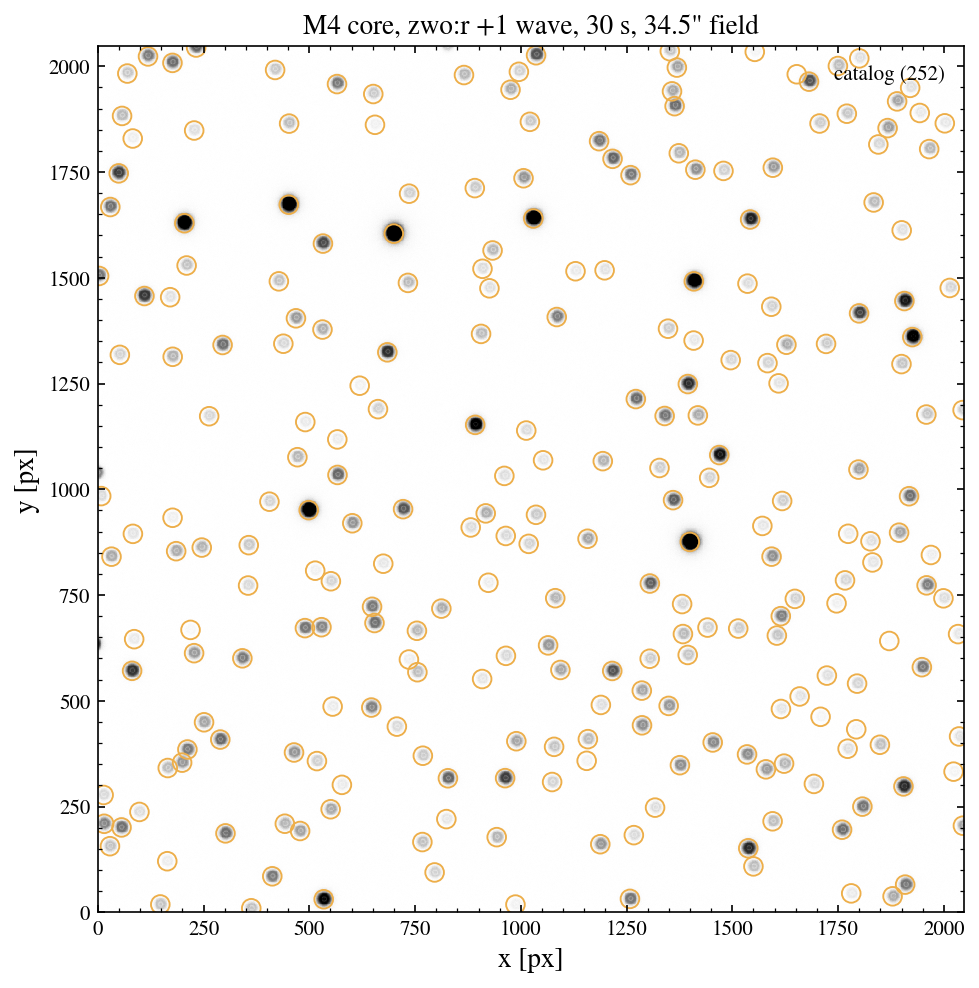

In [4]:
ax = field0.plot(catalog=True)
ax.set_title(f'M4 core, zwo:r +1 wave, {EXPTIME:.0f} s, 34.5\" field')
plt.show()

## Hero figure

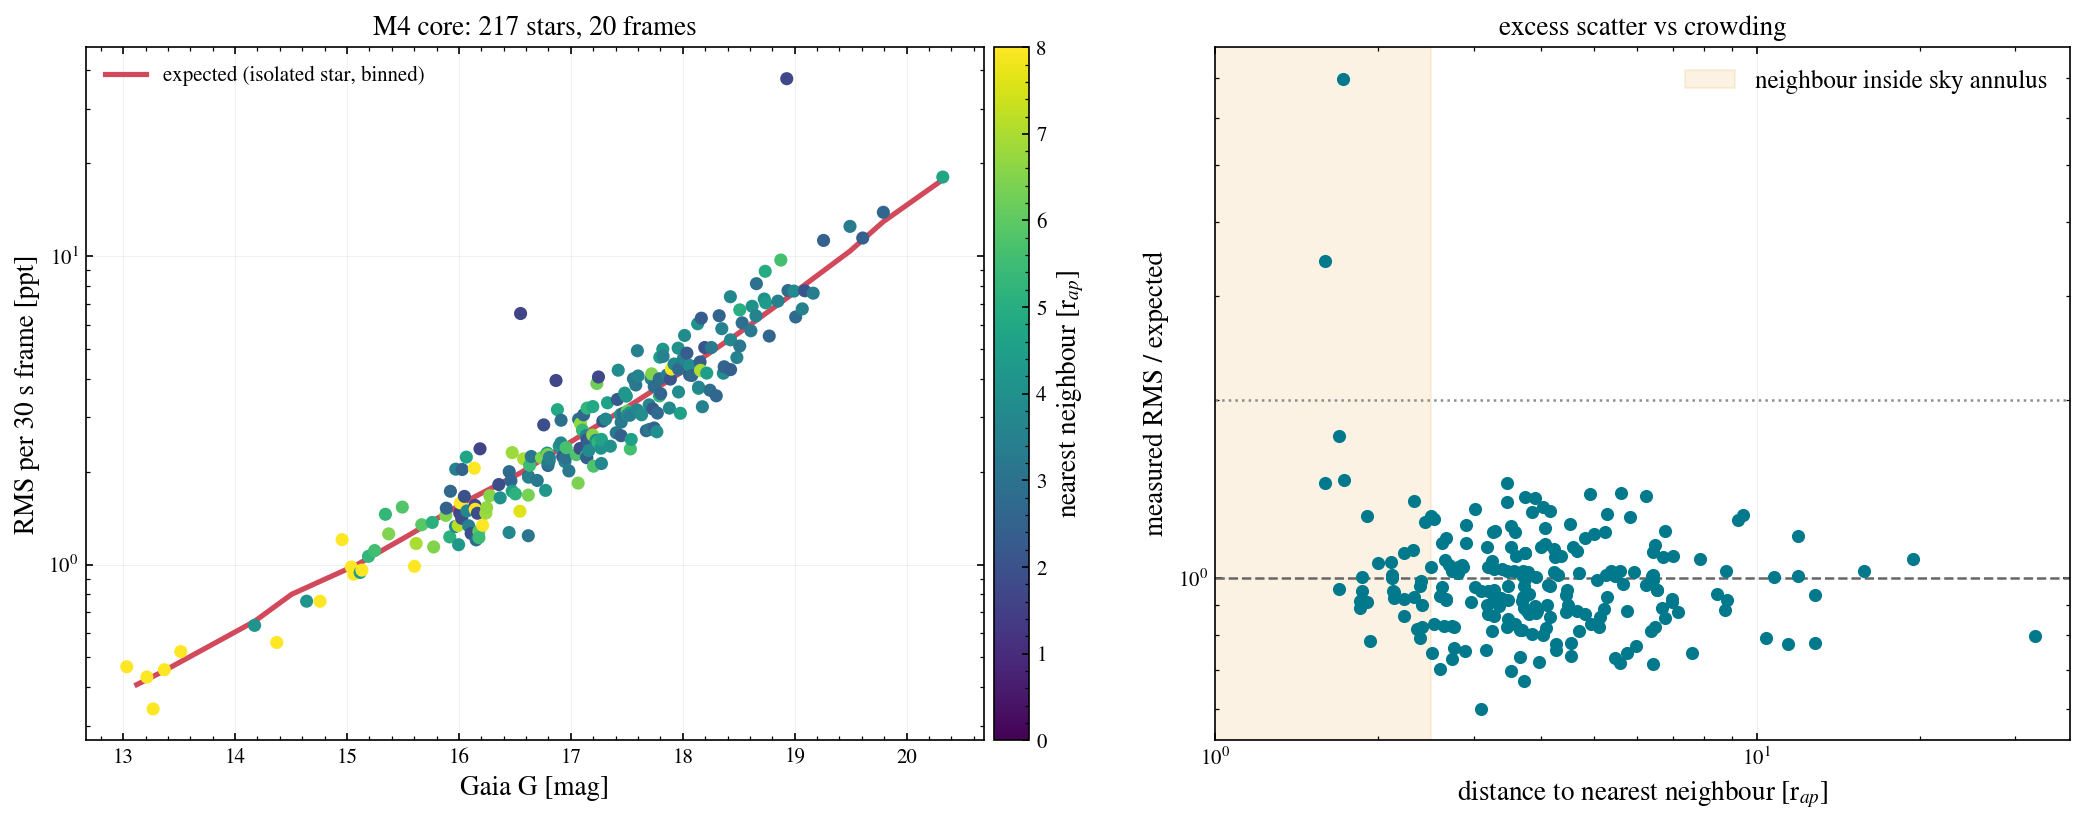

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
dn = np.clip(d_nb / geom.r_ap, 0, 8)
sc = ax1.scatter(g[good], 1e3 * rms[good], c=dn[good], cmap='viridis', s=28, vmin=0, vmax=8, zorder=3)
bins = np.arange(12.75, 21, 0.5)
gb = np.digitize(g[good], bins)
xb = [np.median(g[good][gb == b]) for b in np.unique(gb)]
yb = [np.median(expct[good][gb == b]) for b in np.unique(gb)]
ax1.plot(xb, 1e3 * np.array(yb), color='#d1495b', lw=2.5, label='expected (isolated star, binned)')
ax1.set_yscale('log')
ax1.set_xlabel('Gaia G [mag]')
ax1.set_ylabel(f'RMS per {EXPTIME:.0f} s frame [ppt]')
ax1.set_title(f'M4 core: {good.sum()} stars, {N_FRAMES} frames')
ax1.legend(loc='upper left')
cb = fig.colorbar(sc, ax=ax1, pad=0.01)
cb.set_label('nearest neighbour [r$_{ap}$]')

ax2.scatter(d_nb[good] / geom.r_ap, ratio[good], s=28, color='#00798c', zorder=3)
ax2.axhline(1, color='0.4', ls='--', lw=1.2)
ax2.axhline(2, color='0.55', ls=':', lw=1.2)
ax2.axvspan(0, geom.r_out / geom.r_ap, color='#edae49', alpha=0.15, label='neighbour inside sky annulus')
ax2.set_xscale('log'); ax2.set_yscale('log'); ax2.set_xlim(1, None)
ax2.set_xlabel('distance to nearest neighbour [r$_{ap}$]')
ax2.set_ylabel('measured RMS / expected')
ax2.set_title('excess scatter vs crowding')
ax2.legend(loc='upper right', fontsize=12)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

Barely, at the density Gaia provides. Across 217 unflagged stars (G ≈ 13–20) in the central 34.5″ of M4, the 20-frame light-curve RMS matches the isolated-star CCD-equation expectation (median ratio 0.97). Only 2 stars (0.9%) show more than 2× excess scatter. Both have a neighbour inside the sky annulus: 6% of the 35 such stars versus 0% of the 182 without one. With a 0.35″ defocused aperture, the WCC resolves essentially every Gaia star in the core. The catch is that Gaia itself has no pairs closer than 0.56″ here, so the simulation leaves out the faint, unresolved population that actually limits crowded-field photometry.

## Caveats & next steps

- **The input catalogue sets the crowding.** wcc-sim renders only Gaia DR3 sources (G < 21), and Gaia is badly incomplete in globular-cluster cores: blended pairs are dropped, and the main sequence below the turnoff is missing. Real crowding (and the diffuse light from unresolved stars) is therefore *worse* than simulated. Treat this as a lower limit on the crowding penalty. Every star also gets a dwarf template (no giants or reddening; M4 has E(B−V) ≈ 0.35).
- **Instrument and pipeline limits.** There are no cosmic rays, PRNU, non-linearity or intrapixel response. The read noise carries a ×2 margin, the zodi is constant and the scattered-light halo is monochromatic (450 nm), all per the wcc-sim README. The dithers are only ±0.5 px, so neighbour contamination is nearly static: it biases fluxes (5 stars are off by more than 5%) more than it adds scatter. With 20 frames, each RMS is uncertain by ~16%. The runtime is ~6 s/frame on an idle laptop (much slower under load).
- **Ideas to extend:** (1) add a synthetic deeper luminosity function (an M4-like isochrone down to G ≈ 26 with a King profile) through `simulate_field(catalog=...)` and redo the plot; (2) compare `focus=0` (in focus, smaller aperture) against `focus=1` and `focus=2` to find the defocus that minimises blending for a given brightness; (3) swap aperture photometry for PSF fitting (`wcc_phot.run_photometry(method="psf")`) or difference imaging on the time series.